# 06 — State representation research: the Fatimah version

<div><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#1F3A93;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REPRESENTATION</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span><span style="display:inline-block;background:#8C564B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">HISTORY</span><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span><span style="display:inline-block;background:#B279A2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRANSITION</span><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span></div>

Now take everything from Elder Mist and translate it into the research problem:

> Raw sources come in. What state representation should the harness receive so it can choose good actions?

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-060" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">The research pipeline</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">RAW SOURCES</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-060)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE REPRESENTATION</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-060)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HARNESS / POLICY</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-060)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-060)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OUTCOME</text>
</svg>
</div>


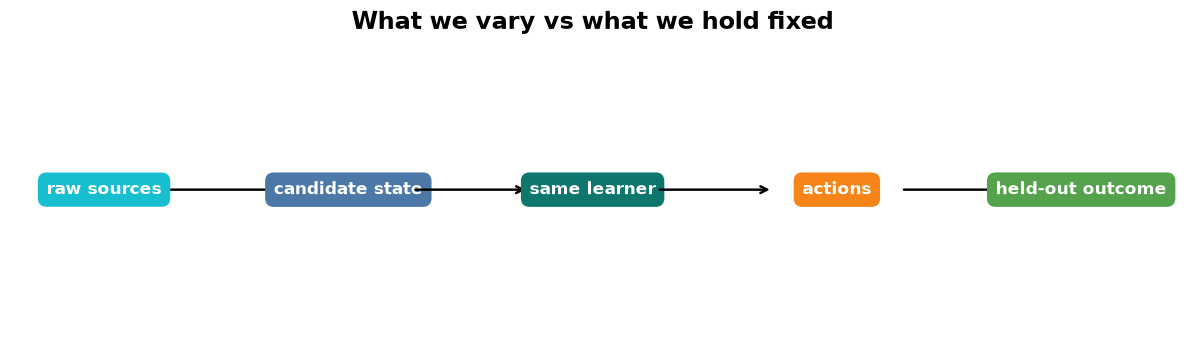

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))

from eldermist import ElderMistReplicaEnv
from eldermist.qlearning import train_q, q_policy
from visuals import pipeline, COLORS

fig = pipeline(
    ["raw sources","candidate state","same learner","actions","held-out outcome"],
    title="What we vary vs what we hold fixed"
)
plt.show()

<div style="border-left:10px solid #1F3A93;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#1F3A93">REPRESENTATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. Telemetry is not automatically state representation</div></div>

Raw inputs might be screenshots, accessibility trees, mouse/keyboard traces, messages, history, or app data.

A representation is the transformation that decides what decision-relevant information survives.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-062" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Raw observations → representation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SCREEN</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-062)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">A11Y TREE</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-062)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HISTORY</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-062)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TRANSFORM</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-062)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE zₜ</text>
</svg>
</div>


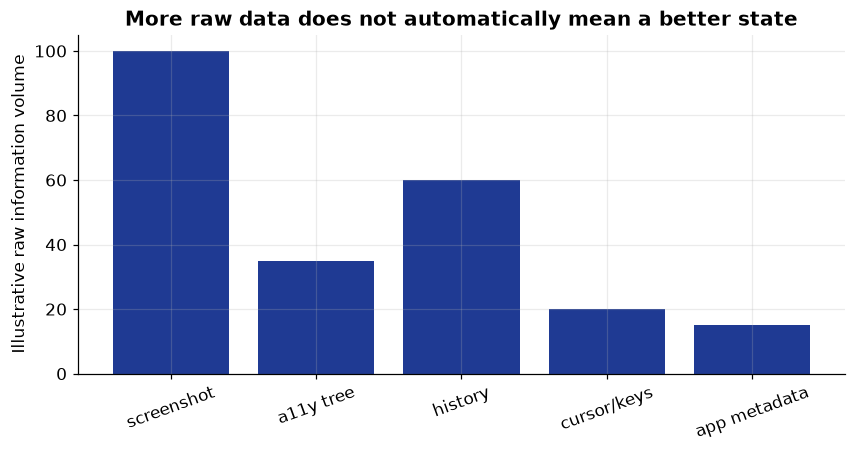

In [2]:
sources = ["screenshot","a11y tree","history","cursor/keys","app metadata"]
raw_size = [100,35,60,20,15]

plt.figure(figsize=(9,4))
plt.bar(sources, raw_size, color=COLORS["REPRESENTATION"])
plt.ylabel("Illustrative raw information volume")
plt.title("More raw data does not automatically mean a better state")
plt.xticks(rotation=20)
plt.show()

<div style="border-left:10px solid #1F3A93;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#1F3A93">REPRESENTATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. Candidate representations</div></div>

In Elder Mist we can compare FULL, NO_SWORD, NO_LOCKS, and MINIMAL.

In computer use, the analogues might be screenshot-only, tree-only, screenshot+tree, or a compact inferred task state.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-064" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Elder Mist candidate states</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FULL</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-064)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NO SWORD</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-064)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NO LOCKS</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-064)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MINIMAL</text>
</svg>
</div>


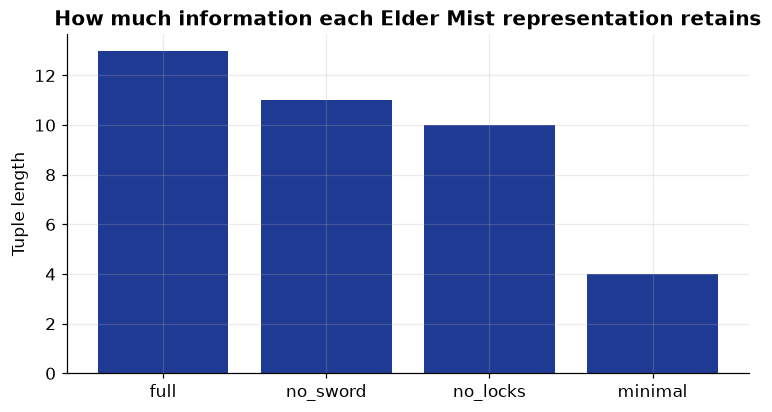

In [3]:
reps = ["full","no_sword","no_locks","minimal"]
envs = {}
sizes = []

for rep in reps:
    e = ElderMistReplicaEnv(representation=rep)
    e.reset(seed=1)
    envs[rep] = e
    sizes.append(len(e.compact_state()))

plt.figure(figsize=(8,4))
plt.bar(reps, sizes, color=COLORS["REPRESENTATION"])
plt.ylabel("Tuple length")
plt.title("How much information each Elder Mist representation retains")
plt.show()

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. Fair comparison means holding the rest fixed</div></div>

If you change the model, task set, training budget, and representation all at once, you cannot tell what caused the result.

So hold constant:

- environment
- task distribution
- learner
- reward
- training budget
- evaluation seeds

Change only the representation.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-066" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Controlled experiment</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME TASKS</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-066)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME LEARNER</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-066)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ONLY REP CHANGES</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-066)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HELD-OUT TEST</text>
</svg>
</div>


,representation,win_rate,avg_turns,avg_counters,fields
0,full,0.108333,27.858333,0.191667,13
1,no_sword,0.333333,31.800000,0.608333,11
2,no_locks,0.566667,34.166667,0.491667,10
3,minimal,0.891667,38.175000,0.066667,4


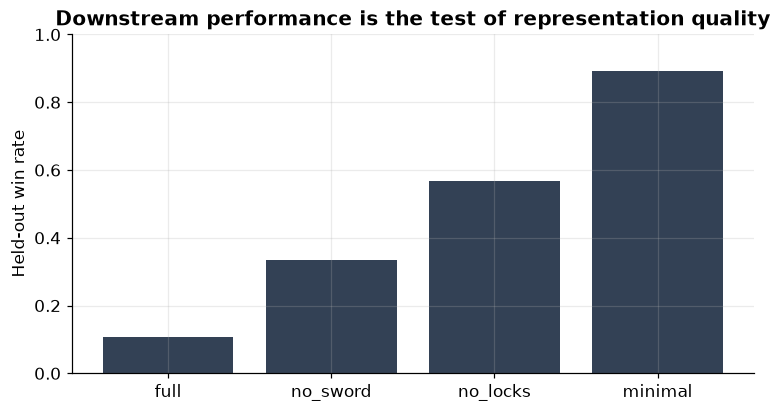

In [4]:
train_episodes = 4000
eval_seeds = range(50000, 50120)
rows = []
models = {}

for rep in reps:
    q, _ = train_q(
        lambda rep=rep: ElderMistReplicaEnv(representation=rep, reward_mode="shaped"),
        episodes=train_episodes,
        seed=123
    )
    models[rep] = q

    wins, turns, counters = [], [], []
    for seed in eval_seeds:
        e = ElderMistReplicaEnv(representation=rep, reward_mode="shaped")
        o,_ = e.reset(seed=seed)
        while True:
            a = q_policy(q, e)
            o,r,term,trunc,_ = e.step(a)
            if term or trunc: break
        wins.append(int(e.state.boss_hp <= 0))
        turns.append(e.state.turn)
        counters.append(e.state.counter_slashes)

    rows.append({
        "representation": rep,
        "win_rate": np.mean(wins),
        "avg_turns": np.mean(turns),
        "avg_counters": np.mean(counters),
        "fields": len(envs[rep].compact_state())
    })

results = pd.DataFrame(rows)
display(results)

plt.figure(figsize=(8,4))
plt.bar(results["representation"], results["win_rate"], color=COLORS["ENVIRONMENT"])
plt.ylim(0,1)
plt.ylabel("Held-out win rate")
plt.title("Downstream performance is the test of representation quality")
plt.show()

<div style="border-left:10px solid #1F3A93;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#1F3A93">REPRESENTATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. Why a representation can fail</div></div>

If Sword-active and Sword-down worlds map to the same representation, the policy cannot choose differently between them.

This is **state aliasing**: strategically different situations collapse into the same input.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-068" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Aliasing destroys useful distinctions</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD A</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-068)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME zₜ</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-068)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD B</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-068)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY CAN&#x27;T DISTINGUISH</text>
</svg>
</div>


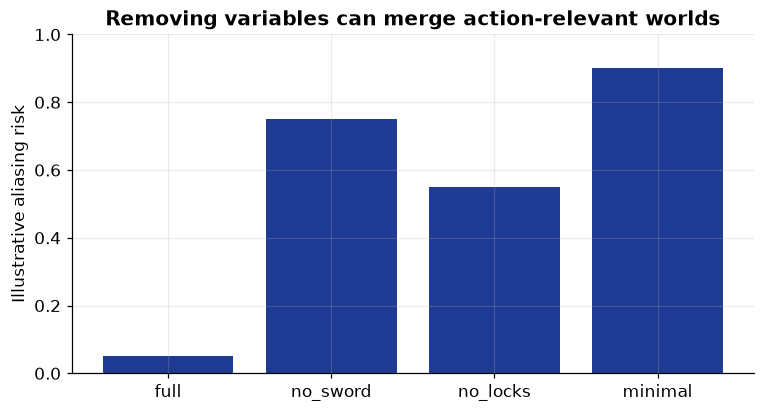

In [5]:
alias_risk = {
    "full": 0.05,
    "no_sword": 0.75,
    "no_locks": 0.55,
    "minimal": 0.90
}

plt.figure(figsize=(8,4))
plt.bar(alias_risk.keys(), alias_risk.values(), color=COLORS["REPRESENTATION"])
plt.ylim(0,1)
plt.ylabel("Illustrative aliasing risk")
plt.title("Removing variables can merge action-relevant worlds")
plt.show()

<div style="border-left:10px solid #54A24B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#54A24B">REWARD</div><div style="font-size:21px;font-weight:800;margin-top:4px">5. “Best” is usually multi-objective</div></div>

A huge state may improve performance but cost more tokens, latency, memory, or inference time.

So compare performance **and** cost.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0610" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">No single metric is always enough</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SUCCESS</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0610)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TOKENS</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0610)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LATENCY</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0610)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TOOL ERRORS</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0610)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">PARETO FRONTIER</text>
</svg>
</div>


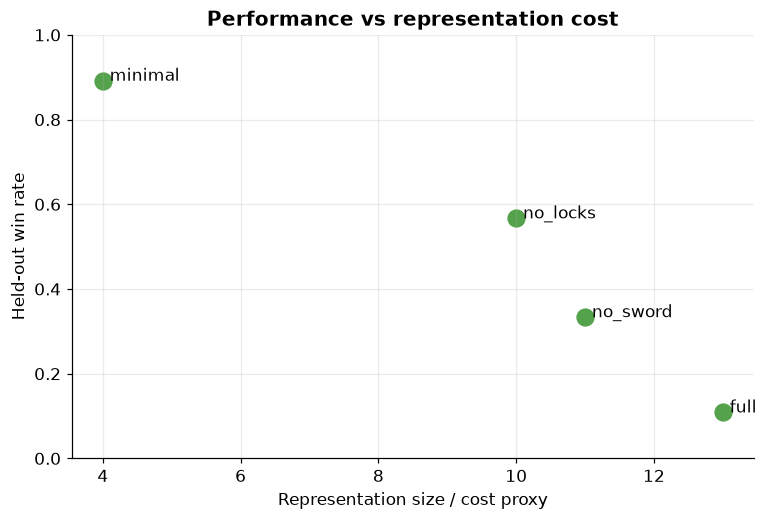

In [6]:
plt.figure(figsize=(8,5))
plt.scatter(results["fields"], results["win_rate"], s=120, color=COLORS["REWARD"])
for _, r in results.iterrows():
    plt.text(r["fields"]+0.1, r["win_rate"], r["representation"])
plt.xlabel("Representation size / cost proxy")
plt.ylabel("Held-out win rate")
plt.ylim(0,1)
plt.title("Performance vs representation cost")
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">6. Map Elder Mist directly to screenshot + accessibility tree</div></div>

The structure of the experiment is identical.

What changes is the source data and the action space.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0612" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Observable Intuition / computer-use analogue</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SCREEN + TREE + HISTORY</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0612)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">zₜ</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0612)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HARNESS π</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0612)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TOOL/UI ACTION</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0612)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TASK SUCCESS</text>
</svg>
</div>


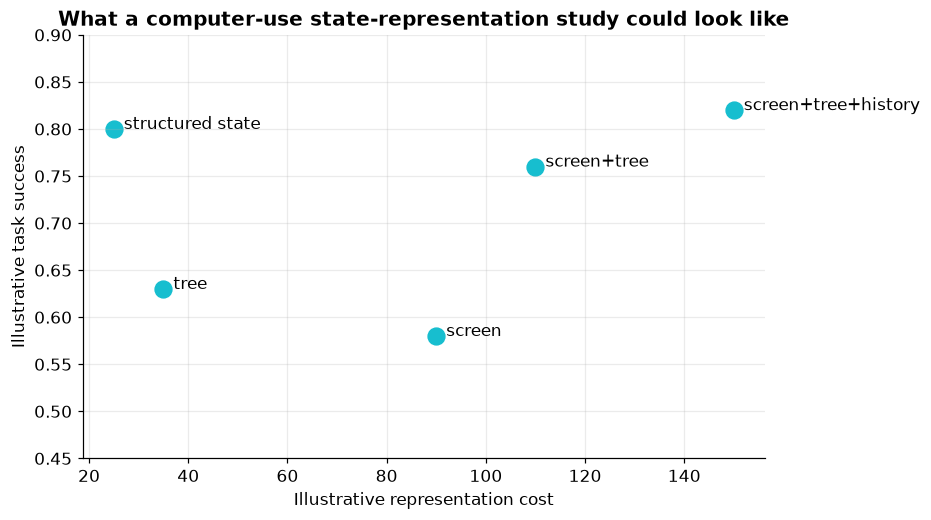

Illustrative only: the point is the experimental design, not these fake numbers.


In [7]:
candidates = ["screen","tree","screen+tree","screen+tree+history","structured state"]
illustrative_cost = [90,35,110,150,25]
illustrative_success = [0.58,0.63,0.76,0.82,0.80]

plt.figure(figsize=(8,5))
plt.scatter(illustrative_cost, illustrative_success, s=120, color=COLORS["OBSERVATION"])
for x,y,n in zip(illustrative_cost,illustrative_success,candidates):
    plt.text(x+2,y,n)
plt.xlabel("Illustrative representation cost")
plt.ylabel("Illustrative task success")
plt.ylim(0.45,0.9)
plt.title("What a computer-use state-representation study could look like")
plt.show()

print("Illustrative only: the point is the experimental design, not these fake numbers.")

<div style="border-left:10px solid #0F766E;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#0F766E">POLICY</div><div style="font-size:21px;font-weight:800;margin-top:4px">7. What does “train the harness” actually mean?</div></div>

You need to identify the parameterized component.

Possibilities include state encoder, retrieval/memory selector, planner, LLM/LoRA, tool-selection policy, or some combination.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0614" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Which component actually learns?</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE ENCODER</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0614)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MEMORY</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0614)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">PLANNER</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0614)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LLM</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0614)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TOOL POLICY</text>
</svg>
</div>


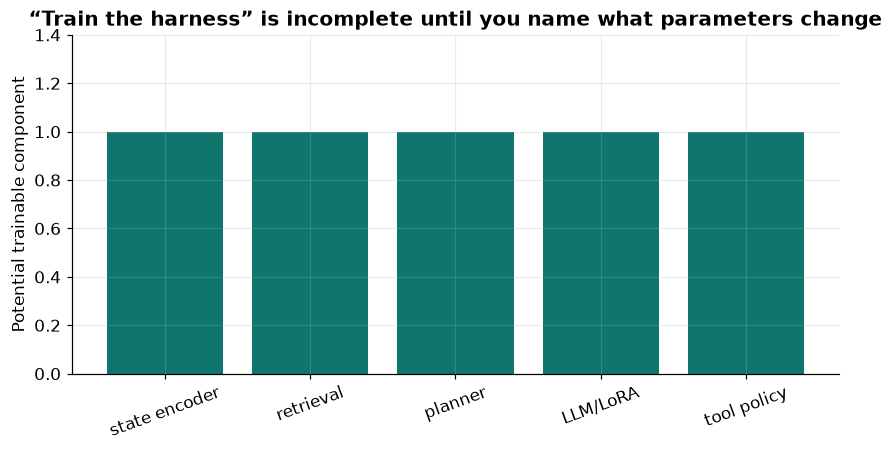

In [8]:
components = ["state encoder","retrieval","planner","LLM/LoRA","tool policy"]
trainable_question = [1,1,1,1,1]

plt.figure(figsize=(9,4))
plt.bar(components, trainable_question, color=COLORS["POLICY"])
plt.ylim(0,1.4)
plt.ylabel("Potential trainable component")
plt.xticks(rotation=20)
plt.title("“Train the harness” is incomplete until you name what parameters change")
plt.show()

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">8. Why τ² helps</div></div>

τ² gives a controlled interactive environment: observations, actions, world transitions, and machine-checkable outcomes.

That makes it useful as a test bed for representation ablations before moving to messier real telemetry.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0616" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Why a benchmark environment matters</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">TASK</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0616)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVE</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0616)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACT</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0616)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#B279A2" stroke="#B279A2" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">WORLD CHANGES</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0616)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ASSERT SUCCESS</text>
</svg>
</div>


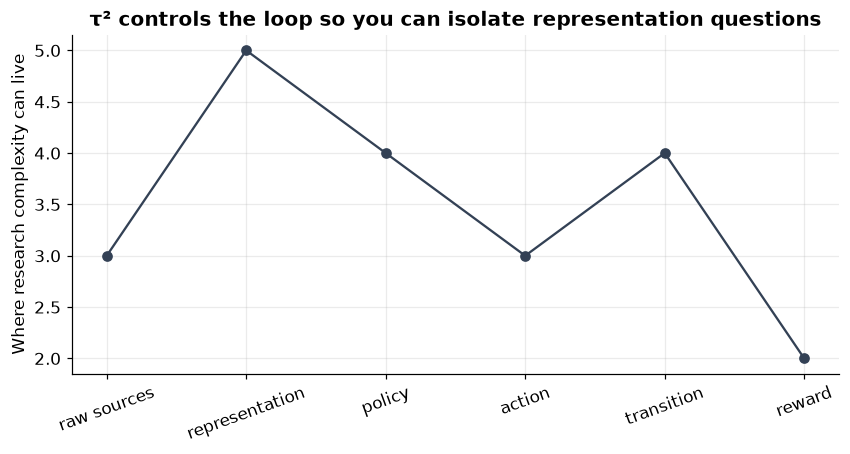

In [9]:
stages = ["raw sources","representation","policy","action","transition","reward"]
difficulty = [3,5,4,3,4,2]

plt.figure(figsize=(9,4))
plt.plot(stages, difficulty, marker="o", color=COLORS["ENVIRONMENT"])
plt.ylabel("Where research complexity can live")
plt.title("τ² controls the loop so you can isolate representation questions")
plt.xticks(rotation=20)
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">9. Questions to bring into the meeting</div></div>

1. What are the raw sources?
2. What is one action?
3. What is one episode?
4. What is hidden?
5. What is reward?
6. Which component learns?
7. How are representations compared fairly?
8. Imitation or outcome optimization?
9. Where is uncertainty represented?
10. What is the smallest sufficient representation?

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0618" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Turn vague research into explicit variables</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SOURCES?</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0618)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">STATE?</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0618)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION?</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0618)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#54A24B" stroke="#54A24B" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">REWARD?</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0618)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LEARNER?</text>
</svg>
</div>


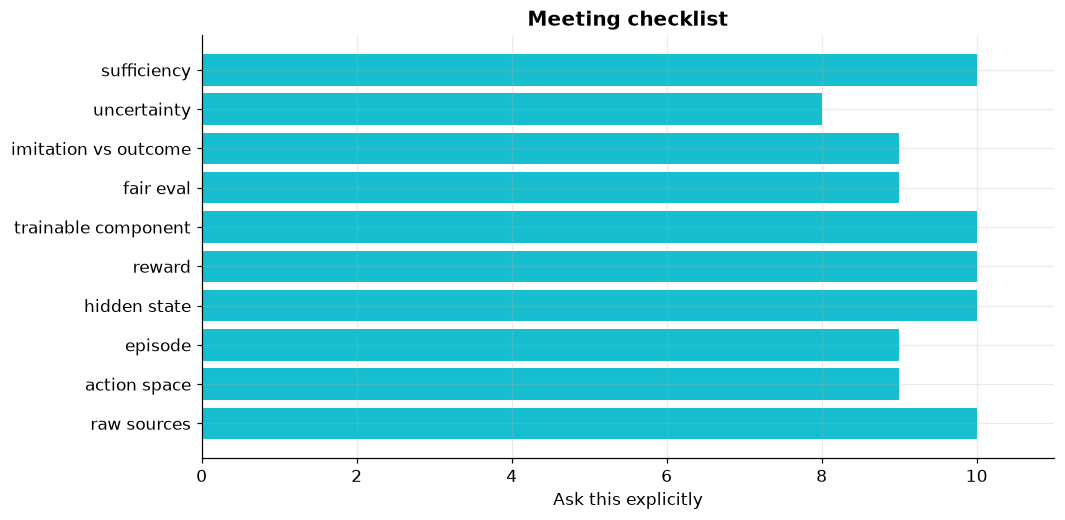

In [10]:
questions = [
    "raw sources","action space","episode","hidden state","reward",
    "trainable component","fair eval","imitation vs outcome","uncertainty","sufficiency"
]
importance = [10,9,9,10,10,10,9,9,8,10]

plt.figure(figsize=(10,5))
plt.barh(questions, importance, color=COLORS["OBSERVATION"])
plt.xlim(0,11)
plt.xlabel("Ask this explicitly")
plt.title("Meeting checklist")
plt.show()

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">KEY IDEA</div><div style="font-size:21px;font-weight:800;margin-top:4px">Final sentence to memorize</div></div>

**State-representation research asks what information the policy must retain so that different future consequences and good actions remain distinguishable.**

You now have the toy experiment, the POMDP extension, the neural-weight extension, and the direct computer-use mapping.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0620" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">The whole point</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">RAW DATA</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0620)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">KEEP WHAT MATTERS</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0620)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY CAN DISTINGUISH</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0620)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BETTER ACTIONS</text>
</svg>
</div>
